# PathSnap — 03 · Model Experimentation & Comparison

Results are produced by `scripts/train_compare.py` (re-run it to reproduce). This notebook only reads the saved results
in `outputs/models/compare/` and builds the comparison tables and figures.

**Protocol**
- **Task:** binary classification of (GPS point, candidate arc) rows; the arc with the highest probability is the point's prediction.
- **Fitting data:** 78 reliable train trips, every 3rd GPS point (1 Hz neighbours are near-duplicates), points whose label is
  within 50 m. KNN and RBF-SVM are capped at 150k and 20k rows because of their cost; the cap samples whole GPS points.
- **Cross-validation:** 5-fold `GroupKFold` by trip. Validation folds are scored on **every** point of the held-out trips, the same
  protocol as student_test.
- **Student-test:** refit on all fitting data, then score all 10 student_test trips.
- **Seed** 42 everywhere; configuration, timings and fold scores are logged per model.

**Primary selection metric: observation-level Top-1 accuracy.** Map-matching needs the right arc per point, not a good threshold
on rows. Row-level Macro F1 depends on a 0.5 threshold that the system never uses. **Log loss** is the secondary metric because the
HMM (stage 7) uses the probabilities directly as emission scores, so they must be well calibrated.

In [1]:
import os, sys, json, glob, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.evaluation import top1_choice, route_continuity, all_metrics
RES = '../outputs/models/compare'; FIG = f'{RES}/figures'; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 80)
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()
ORDER = ['LogisticRegression', 'GaussianNB', 'KNN', 'SVM_RBF', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'MLP']
R = {n: json.load(open(f'{RES}/{n}.json')) for n in ORDER if os.path.exists(f'{RES}/{n}.json')}
CV = pd.concat([pd.read_csv(f'{RES}/{n}_cv.csv') for n in R], ignore_index=True)
ORDER = [n for n in ORDER if n in R]
print('models with results:', ORDER)
json.load(open(f'{RES}/experiment_config.json'))

models with results: ['LogisticRegression', 'GaussianNB', 'KNN', 'SVM_RBF', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'MLP']


{'seed': 42,
 'point_stride': 3,
 'n_folds': 5,
 'cv': 'GroupKFold by trip',
 'training_filter': 'fit: trip_reliable==1 & label_ok==1 & point_idx%3==0; CV scoring: all points of held-out reliable trips',
 'features': ['dist',
  'dist_rank',
  'dist_minus_min',
  'dist_ratio_min',
  'gauss_share',
  'n_cands',
  'proj_frac',
  'dist_to_end_min',
  'arc_len',
  'heading_diff',
  'heading_diff_undirected',
  'heading_reliable',
  'speed',
  'accel',
  'dt_prev',
  'dt_next',
  'turn_rate',
  'dist_prev1',
  'dist_prev2',
  'dist_next1',
  'dist_next2',
  'ctx_mean_dist',
  'from_out_deg',
  'to_in_deg',
  'to_out_deg',
  'has_reverse'],
 'python': '3.14.8',
 'sklearn': '1.9.1',
 'numpy': '2.5.5',
 'machine': 'macOS-26.5.2-arm64-arm-64bit-Mach-O'}

## 1. Reference points: rule baselines and label ceiling

In [2]:
test = pd.read_parquet('../outputs/features/student_test.parquet')
part = {t: 'student_test' for t in test.trip.unique()}
truth = test[test.y == 1].drop_duplicates(['trip', 'point_idx'])
ceiling = test.groupby(['trip', 'point_idx']).y.max().mean()
ref_cont = route_continuity(truth.sort_values(['trip', 'point_idx'])[['trip', 'point_idx', 'arc_id']], part)
rules = {'Rule: nearest arc': -test.dist.to_numpy(),
         'Rule: nearest + heading': -(test.dist / 5.0) ** 2 / 2 - (test.heading_diff / 30.0) ** 2 / 2}
base = pd.DataFrame({k: {'top1_accuracy': top1_choice(test, s).y.mean(),
                         'route_continuity': route_continuity(top1_choice(test, s), part)} for k, s in rules.items()}).T
print(f'Top-1 ceiling (true arc present among candidates): {ceiling:.4f}')
print(f'Route continuity of the reference labels themselves: {ref_cont:.4f}')
base.round(4)

Top-1 ceiling (true arc present among candidates): 0.9979
Route continuity of the reference labels themselves: 0.9974


,top1_accuracy,route_continuity
Rule: nearest arc,0.5383,0.9010
Rule: nearest + heading,0.8326,0.9485


## 2. Overall model comparison (report table 3.1)

In [3]:
cvagg = CV.groupby('model').agg(cv_macro_f1=('macro_f1', 'mean'), cv_macro_f1_std=('macro_f1', 'std'),
                                cv_top1=('top1_accuracy', 'mean'), cv_top1_std=('top1_accuracy', 'std'),
                                cv_log_loss=('log_loss', 'mean'), cv_continuity=('route_continuity', 'mean'))
rows = []
for n in ORDER:
    r = R[n]; t = r['test']
    rows.append(dict(model=n, family=r['family'], key_configuration=r['config'],
                     cv_macro_f1=f"{cvagg.loc[n, 'cv_macro_f1']:.4f} ± {cvagg.loc[n, 'cv_macro_f1_std']:.4f}",
                     cv_top1=f"{cvagg.loc[n, 'cv_top1']:.4f} ± {cvagg.loc[n, 'cv_top1_std']:.4f}",
                     test_top1=t['top1_accuracy'], test_route_continuity=t['route_continuity'],
                     test_macro_f1=t['macro_f1'], test_precision=t['precision'], test_recall=t['recall'],
                     test_log_loss=t['log_loss'], train_rows=r['n_train_rows'], train_time_s=r['train_time_s'],
                     inference_ms_per_1k_rows=r['inference_ms_per_1k_rows']))
table = pd.DataFrame(rows).set_index('model')
table.to_csv(f'{RES}/comparison_table.csv')
table.style.format(precision=4).background_gradient(subset=['test_top1', 'test_macro_f1'], cmap='Greens') \
     .background_gradient(subset=['test_log_loss', 'inference_ms_per_1k_rows'], cmap='Reds')

,family,key_configuration,cv_macro_f1,cv_top1,test_top1,test_route_continuity,test_macro_f1,test_precision,test_recall,test_log_loss,train_rows,train_time_s,inference_ms_per_1k_rows
model,,,,,,,,,,,,,
LogisticRegression,Linear / probabilistic,"L2, C=1.0, lbfgs, max_iter=2000, standardised",0.8945 ± 0.0230,0.8357 ± 0.0448,0.8487,0.9557,0.9021,0.8437,0.8153,0.1234,423491,0.2462,0.0337
GaussianNB,Probabilistic (generative),"var_smoothing=1e-9, quantile-normal transformed inputs",0.7912 ± 0.0127,0.5745 ± 0.0243,0.5542,0.9066,0.7886,0.5113,0.9050,1.5383,423491,0.7261,1.3167
KNN,Instance-based,"k=25, distance-weighted, Euclidean, standardised",0.8979 ± 0.0243,0.8356 ± 0.0475,0.8489,0.9578,0.9063,0.8816,0.7947,0.1278,150574,0.0125,55.3258
SVM_RBF,Kernel-based,"RBF, C=1.0, gamma='scale', Platt-scaled probabilities, standardised",0.8991 ± 0.0241,0.8401 ± 0.0469,0.8538,0.9588,0.9084,0.8971,0.7884,0.1203,19787,4.5670,78.0248
RandomForest,Ensemble (bagging),"300 trees, max_depth=None, min_samples_leaf=5, max_features='sqrt'",0.9160 ± 0.0272,0.8547 ± 0.0479,0.8730,0.9618,0.9250,0.8963,0.8432,0.0827,423491,62.5006,3.2342
HistGradientBoosting,Boosting,"lr=0.1, max_iter=300, max_leaf_nodes=31, early stopping (10% val, patience 20)",0.9148 ± 0.0273,0.8540 ± 0.0486,0.8722,0.9599,0.9247,0.8808,0.8570,0.0875,423491,2.9717,0.8382
LightGBM,Boosting,"lr=0.05, num_leaves=31, min_child_samples=20, subsample=0.8, colsample=0.8, <=2000 rounds, early stop on 10% trip-grouped val (patience 50, keeps best round)",0.9161 ± 0.0279,0.8572 ± 0.0495,0.8733,0.9625,0.9260,0.8856,0.8566,0.0812,423491,3.1941,1.1148
MLP,Neural network,"hidden=(64, 32), ReLU, Adam lr=1e-3, batch=512, alpha=1e-4, <=40 epochs, early stop (patience 5)",0.9102 ± 0.0274,0.8505 ± 0.0492,0.8725,0.9672,0.9211,0.8882,0.8376,0.0845,423491,11.8170,0.0939


## 3. Visual comparison

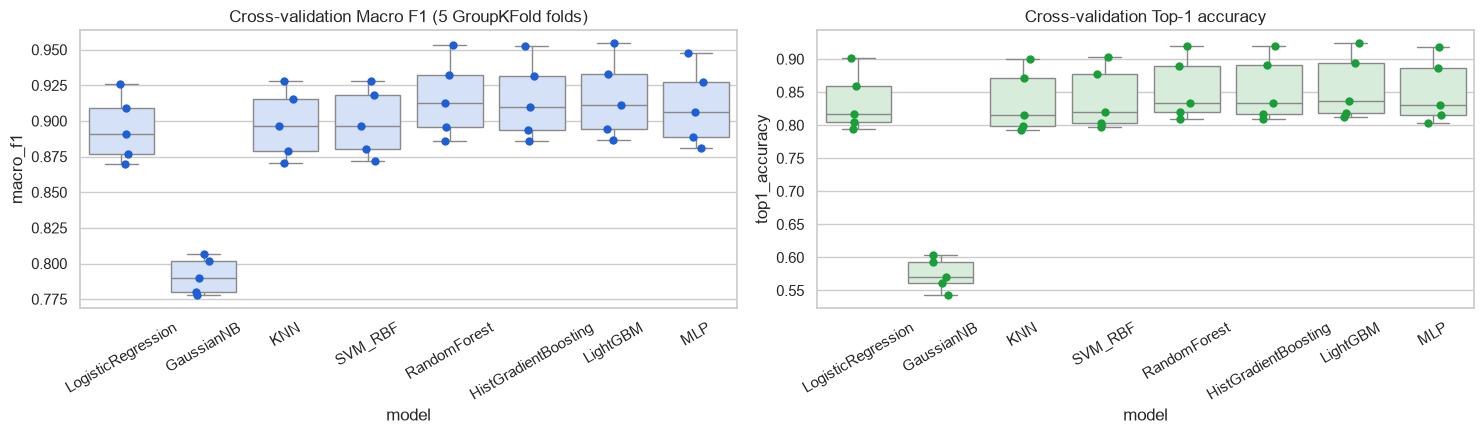

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=CV, x='model', y='macro_f1', order=ORDER, ax=ax[0], color='#cfe0fb')
sns.stripplot(data=CV, x='model', y='macro_f1', order=ORDER, ax=ax[0], color='#1f5fd6', size=6)
ax[0].set_title('Cross-validation Macro F1 (5 GroupKFold folds)'); ax[0].tick_params(axis='x', rotation=30)
sns.boxplot(data=CV, x='model', y='top1_accuracy', order=ORDER, ax=ax[1], color='#d3f0d9')
sns.stripplot(data=CV, x='model', y='top1_accuracy', order=ORDER, ax=ax[1], color='#1a9e3a', size=6)
ax[1].set_title('Cross-validation Top-1 accuracy'); ax[1].tick_params(axis='x', rotation=30)
savefig('01_cv_comparison')

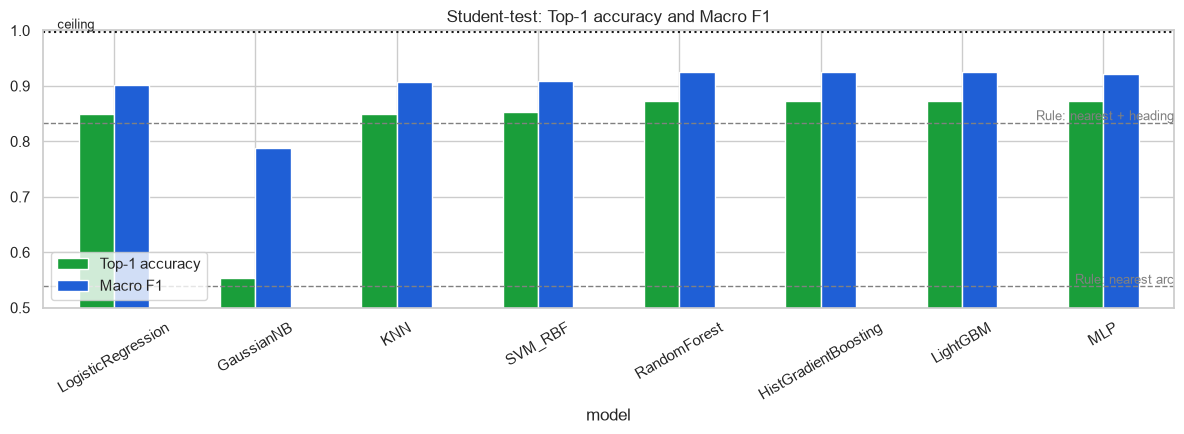

In [5]:
t = table[['test_top1', 'test_macro_f1']].rename(columns={'test_top1': 'Top-1 accuracy', 'test_macro_f1': 'Macro F1'})
ax = t.plot.bar(figsize=(12, 4.5), color=['#1a9e3a', '#1f5fd6'], rot=30)
for name, s in rules.items():
    ax.axhline(base.loc[name, 'top1_accuracy'], ls='--', lw=1, c='grey')
    ax.text(len(t) - 0.5, base.loc[name, 'top1_accuracy'], name, va='bottom', ha='right', fontsize=9, color='grey')
ax.axhline(ceiling, ls=':', c='k'); ax.text(-0.4, ceiling, 'ceiling', va='bottom', fontsize=9)
ax.set_ylim(0.5, 1.0); ax.set_title('Student-test: Top-1 accuracy and Macro F1'); ax.legend(loc='lower left')
savefig('02_student_test_top1_f1')

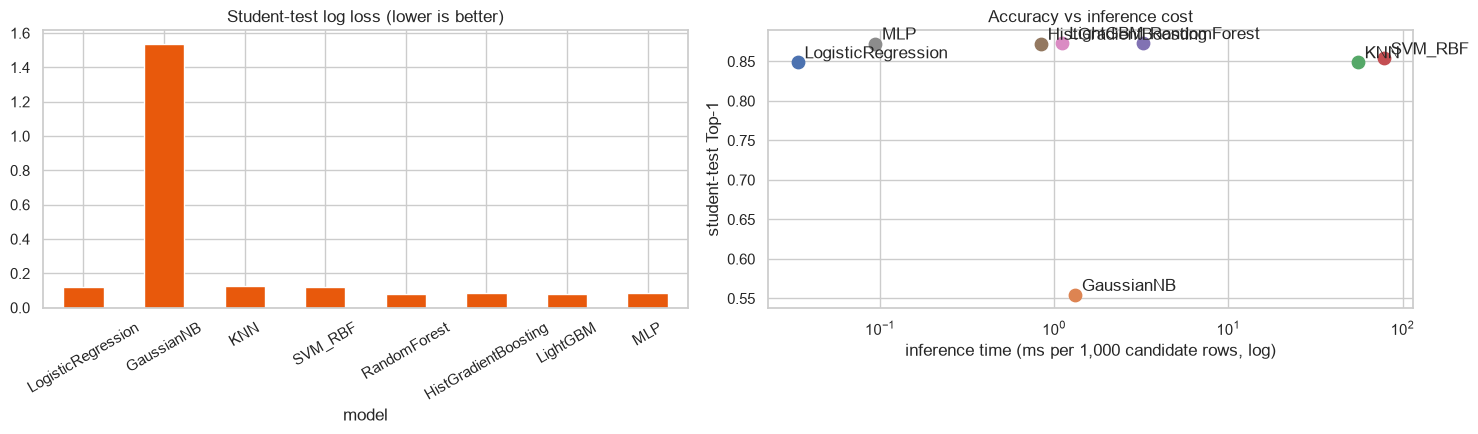

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
table['test_log_loss'].plot.bar(ax=ax[0], color='#e8590c', rot=30); ax[0].set_title('Student-test log loss (lower is better)')
for n in ORDER:
    ax[1].scatter(table.loc[n, 'inference_ms_per_1k_rows'], table.loc[n, 'test_top1'], s=80)
    ax[1].annotate(n, (table.loc[n, 'inference_ms_per_1k_rows'], table.loc[n, 'test_top1']), xytext=(5, 3), textcoords='offset points')
ax[1].set_xscale('log'); ax[1].set_xlabel('inference time (ms per 1,000 candidate rows, log)'); ax[1].set_ylabel('student-test Top-1')
ax[1].set_title('Accuracy vs inference cost')
savefig('03_logloss_and_speed')

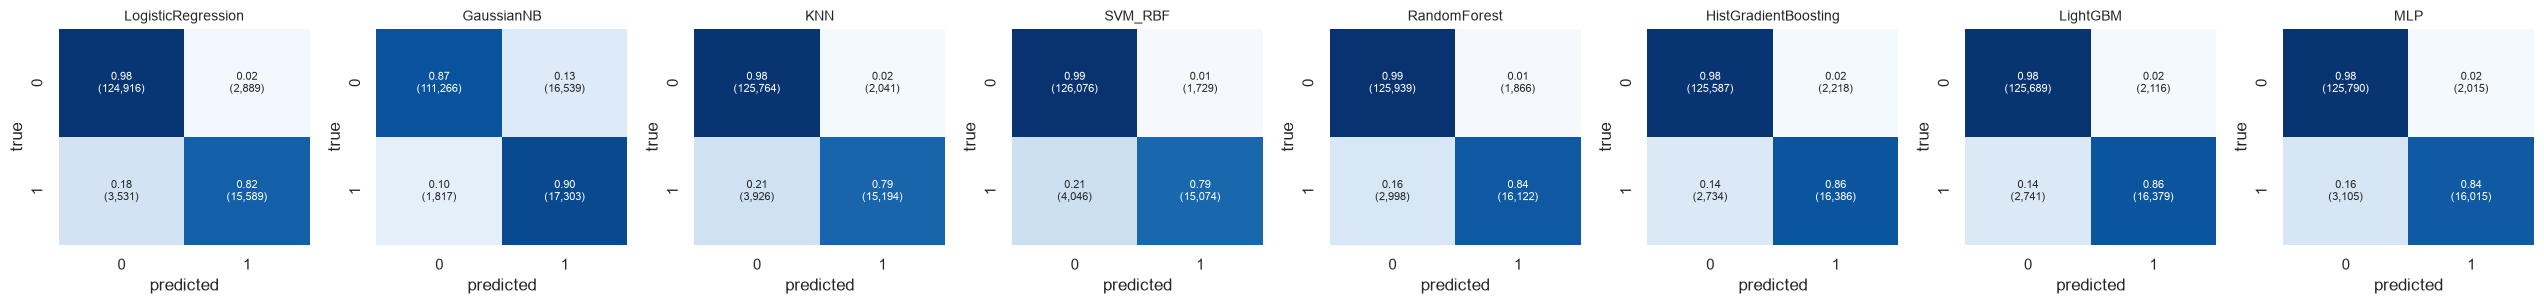

In [7]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(3.2 * len(ORDER), 3.2))
for ax, n in zip(np.atleast_1d(axes), ORDER):
    cm = np.array(R[n]['confusion_matrix']); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f'{v:.2f}\n({c:,})' for v, c in zip(rv, rc)] for rv, rc in zip(cmn, cm)]),
                fmt='', cmap='Blues', cbar=False, vmin=0, vmax=1, ax=ax, annot_kws={'size': 8})
    ax.set_title(n, fontsize=10); ax.set_xlabel('predicted'); ax.set_ylabel('true')
savefig('04_confusion_matrices')

## 4. Training histories (only models that actually have them)

The MLP is trained epoch by epoch, with the validation loss measured on a 10% trip-grouped split. HistGradientBoosting records
the loss after each boosting iteration on its internal 10% early-stopping split. The other models have no iterative history,
so none is plotted for them.

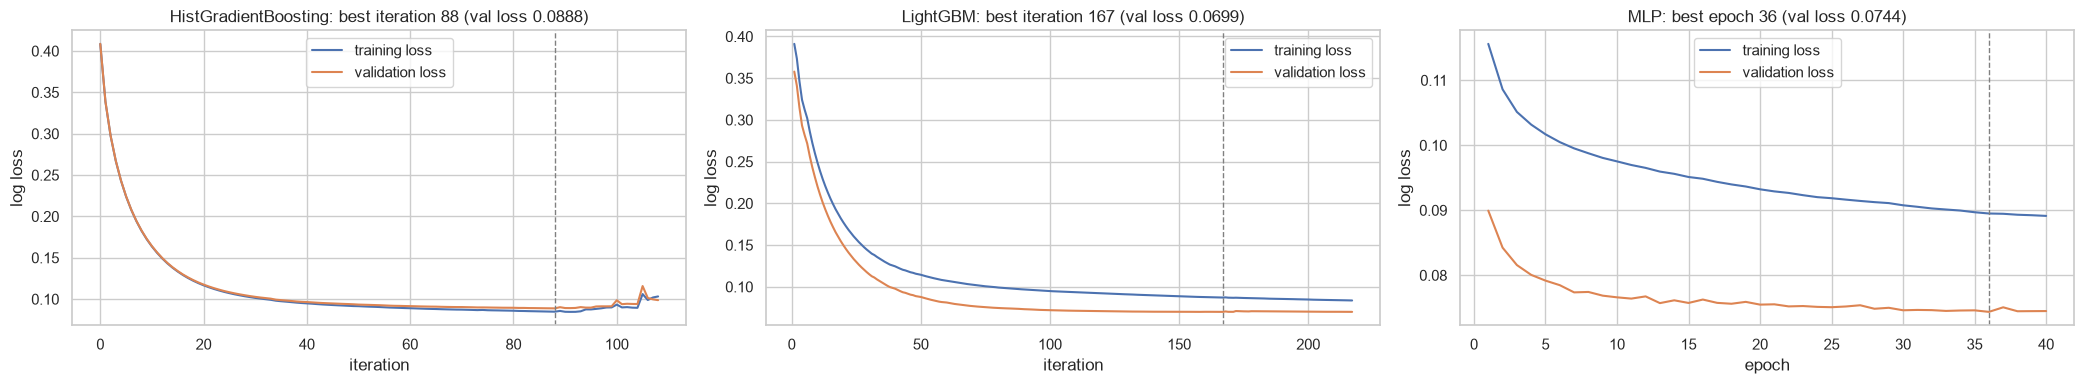

In [8]:
hist_models = [n for n in ORDER if R[n].get('history')]
fig, axes = plt.subplots(1, len(hist_models), figsize=(7 * len(hist_models), 4))
for ax, n in zip(np.atleast_1d(axes), hist_models):
    h = pd.DataFrame(R[n]['history']); x = 'epoch' if 'epoch' in h else 'iteration'
    ax.plot(h[x], h.train_loss, label='training loss'); ax.plot(h[x], h.val_loss, label='validation loss')
    best = h.val_loss.idxmin(); ax.axvline(h[x][best], ls='--', c='grey', lw=1)
    ax.set_xlabel(x); ax.set_ylabel('log loss'); ax.set_title(f'{n}: best {x} {h[x][best]} (val loss {h.val_loss[best]:.4f})'); ax.legend()
savefig('05_training_curves')

## 5. Over- / under-fitting evidence: training folds vs held-out folds vs student-test

In [9]:
fit = []
for n in ORDER:
    trm = R[n]['last_fold_train_metrics']; va = CV[(CV.model == n) & (CV.fold == CV.fold.max())].iloc[0]; te = R[n]['test']
    fit.append(dict(model=n, train_top1=trm['top1_accuracy'], val_top1=va.top1_accuracy, test_top1=te['top1_accuracy'],
                    gap_train_minus_val=trm['top1_accuracy'] - va.top1_accuracy,
                    train_log_loss=trm['log_loss'], val_log_loss=va.log_loss, test_log_loss=te['log_loss']))
fit = pd.DataFrame(fit).set_index('model'); fit.to_csv(f'{RES}/fit_diagnostics.csv'); fit.round(4)

,train_top1,val_top1,test_top1,gap_train_minus_val,train_log_loss,val_log_loss,test_log_loss
model,,,,,,,
LogisticRegression,0.8466,0.7935,0.8487,0.0531,0.1339,0.1773,0.1234
GaussianNB,0.5826,0.5430,0.5542,0.0396,1.5716,1.9849,1.5383
KNN,0.8778,0.7923,0.8489,0.0855,0.1068,0.2053,0.1278
SVM_RBF,0.8559,0.7971,0.8538,0.0588,0.1223,0.1766,0.1203
RandomForest,0.8998,0.8096,0.8730,0.0902,0.0712,0.1339,0.0827
HistGradientBoosting,0.8817,0.8088,0.8722,0.0729,0.0798,0.1359,0.0875
LightGBM,0.8881,0.8121,0.8733,0.0760,0.0741,0.1331,0.0812
MLP,0.8732,0.8027,0.8725,0.0704,0.0888,0.1463,0.0845


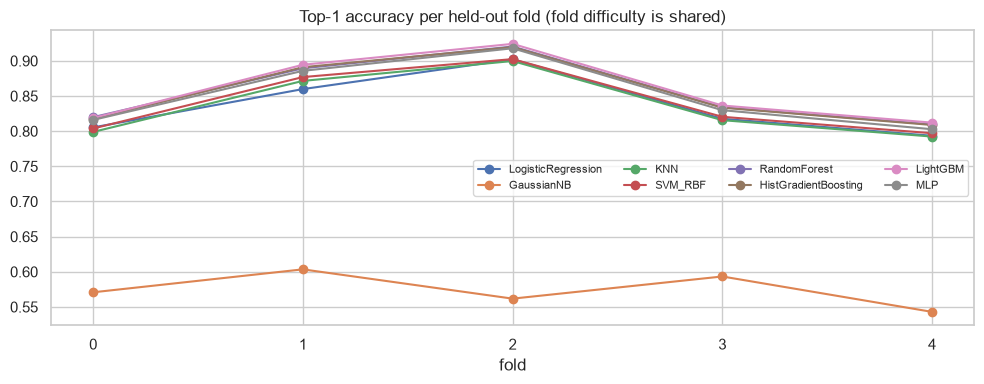

Per-fold rank of each model (1 = best):
model  LogisticRegression  GaussianNB  KNN  SVM_RBF  RandomForest  HistGradientBoosting  LightGBM  MLP
fold                                                                                                  
0                       5           8    7        6             1                     3         2    4
1                       7           8    6        5             3                     2         1    4
2                       6           8    7        5             2                     3         1    4
3                       6           8    7        5             2                     3         1    4
4                       6           8    7        5             2                     3         1    4


In [10]:
cvw = CV.pivot(index='fold', columns='model', values='top1_accuracy')[ORDER]
ax = cvw.plot(marker='o', figsize=(10, 4)); ax.set_title('Top-1 accuracy per held-out fold (fold difficulty is shared)')
ax.set_xticks(cvw.index); ax.legend(ncol=4, fontsize=8)
savefig('06_per_fold_top1')
print('Per-fold rank of each model (1 = best):'); print(cvw.rank(axis=1, ascending=False).astype(int))

## 7. Model selection (stage 5)

| Criterion | Evidence (tables and figures above) |
|---|---|
| Generalisation (primary metric: CV Top-1) | Four models are close: LightGBM 0.857, Random Forest 0.855, HistGradientBoosting 0.854, MLP 0.851. The fold-to-fold spread (about ±0.049) is much larger than the gaps between them |
| Stability across folds | Every model rises and falls with the same folds (fold difficulty is shared). LightGBM wins 4 of 5 folds untuned; the boosting models and RF stay in the top group on every fold |
| Probability quality (HMM emissions) | LightGBM 0.081, RF 0.083, MLP 0.085 and HGB 0.088 test log loss, far better than SVM, LR and KNN (0.12–0.13). Gaussian NB is badly overconfident (1.54) because its independence assumption double-counts the correlated distance features |
| Computational cost | Training: HGB 3.0 s, LightGBM 3.2 s, MLP 11.8 s, RF 62.5 s. Model size: HGB about 190 KB, RF 71 MB. KNN and SVM inference is 50–90× slower than the boosting models |
| Room to improve | The untuned HGB uses learning rate 0.1 with no L2: its validation loss is lowest at iteration 88 and jumps near iteration 105, and sklearn's early stopping keeps the trees after the best iteration, so the untuned configuration is clearly sub-optimal |

**Shortlist for Bayesian optimisation: the two boosting models.** HistGradientBoosting was selected first. LightGBM was then added and
turned out to be the best *untuned* model, so both received the same Bayesian search (notebook 04).

**Final model: tuned HistGradientBoosting.** During the search, tuned HGB reached the highest cross-validated Top-1 (0.8609 vs 0.8597 for
the best LightGBM trial). After the candidate tie-break fix (candidates ordered by distance, then `arc_id`), the same HGB
hyperparameters were refit and re-scored on the same folds: **CV Top-1 0.8597** (notebook 04). That is level with the best tuned
LightGBM, so on accuracy the two are tied within fold noise. The deciding factors are therefore practical. HGB is plain scikit-learn,
while LightGBM needed the `libomp` runtime installed before it would import, a deployment risk on the API laptop. HGB's probabilities
also feed the HMM well (stage 7). RF was not chosen because it costs about 20× more to train and is about 380× larger. The MLP was not
chosen because its results depend more on its early-stopping split. Student-test results were not used to choose.